In [1]:
from backend.tools import *
from backend.get_pars import *
import matplotlib.pyplot as plt

In [2]:
get_pars("2024-11-18")

[(0.08333333333333333, 4.7),
 (0.16666666666666666, 4.65),
 (0.25, 4.63),
 (0.3333333333333333, 4.52),
 (0.5, 4.44),
 (1.0, 4.33),
 (2.0, 4.29),
 (3.0, 4.25),
 (5.0, 4.28),
 (7.0, 4.35),
 (10.0, 4.42),
 (20.0, 4.7),
 (30.0, 4.61)]

In [20]:
# 11/18/24
par_yields = [
    (1/12, 4.7),
    (0.25, 4.63),
    (0.5, 4.44),
    (1.0, 4.33),
    (2.0, 4.29),
    (3.0, 4.25),
    (5.0, 4.28),
    (7.0, 4.35),
    (10.0, 4.42),
    (20, 4.7),
    (30, 4.61)
]

R_t, D_t = bootstrap_D_from_par_yields(par_yields, freq=2, returnR=True, percentize=True)

Zc_t = D_to_Zc(D_t)
Zm_t = D_to_Zm(D_t, 12)

_t = [t for t,_ in par_yields]
Dnodes = [(t,d) for t,d in D_t if t in _t]
Dlog = log_interpolate_Dm(Dnodes)
Zlog = D_to_Zc(Dlog)


print("tau,\t R_t,\t\t D_t,\t\t\t Zm_t")
print("=====================================")
for i in range(len(D_t)):
    r = R_t[i]
    d = D_t[i]
    z = Zm_t[i]

    if r[0] in [0.5,1.0,2.0,3.0,5.0] :
        print(f"{r[0]:.3f},\t {r[1]:.4f},\t {d[1]:.7f},\t {z[1]/12:.5%}")
print()

tau,	 R_t,		 D_t,			 Zm_t
0.500,	 0.0444,	 0.9782821,	 0.36662%
1.000,	 0.0433,	 0.9580778,	 0.35752%
2.000,	 0.0429,	 0.9186390,	 0.35422%
3.000,	 0.0425,	 0.8815439,	 0.35084%
5.000,	 0.0428,	 0.8091546,	 0.35357%



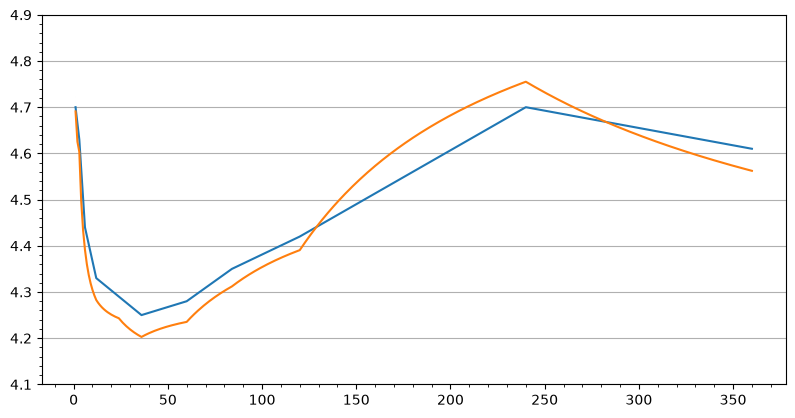

In [21]:
# ===========================================
# Plotting
tt, rr = zip(*R_t)

tt=[12*t for t in tt] # tau -> months
rr=[100*r for r in rr] # percentage

tt12, zz12 = zip(*Zlog)
tt12 = [12*t for t in tt12]
zz12 = [100*z for z in zz12]

fig, ax = plt.subplots(1,1,figsize=plt.figaspect(0.5))

ax.plot(tt, rr)
ax.plot(tt12,zz12)

ax.set_ylim(4.1, 4.9)
ax.minorticks_on()
ax.grid(axis="y")
plt.show()

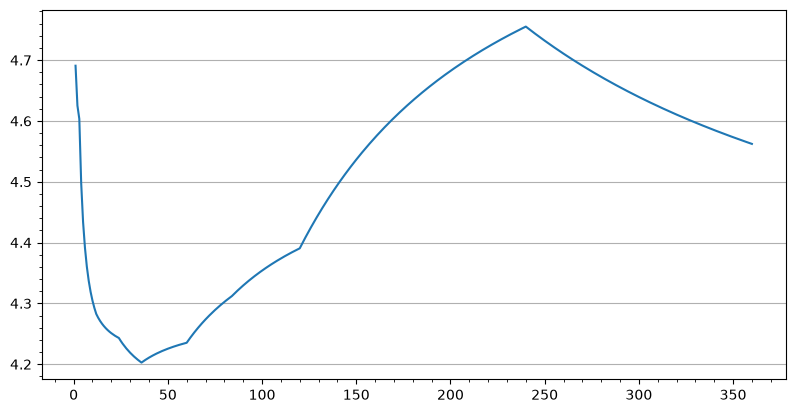

In [16]:
# ===========================================
# Plotting
tt, rr = zip(*Zlog)

tt=[12*t for t in tt] # tau -> months
rr=[100*r for r in rr] # percentage

fig, ax = plt.subplots(1,1,figsize=plt.figaspect(0.5))

ax.plot(tt, rr)
# ax.plot(tt12,zz12)

# ax.set_ylim(90, 100)
# ax.set_xlim(0,80)
ax.minorticks_on()
ax.grid(axis="y")
plt.show()